# Propagation of Hollow Core waveguide at low loss wavelength

Propagating input fields in a device capable of resonant behavior.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from slab2 import Slab, Propagator, real_contour

plt.style.use('dark_background')
%matplotlib widget

# Setup Waveguide and input fields

In [6]:
A = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[100, 40, 300, 40, 100], wl=5.83e-06)

In [7]:
half_width = 1
shift = .5
amplitude = 1

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

f0 = quadratic_piecewise

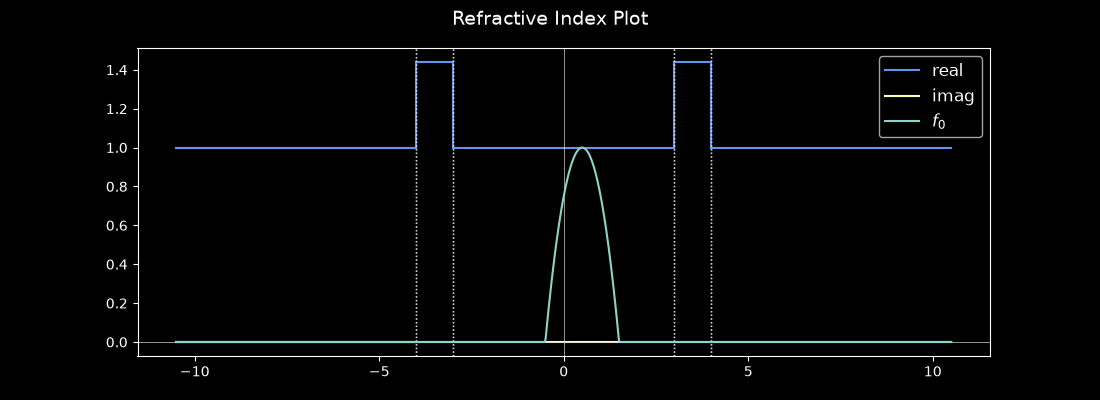

In [8]:
A.plot_refractive_index();
A.add_1d_plot(f0, label='$f_0$')

# Guided Modes

The hollow core fiber does support guided modes:

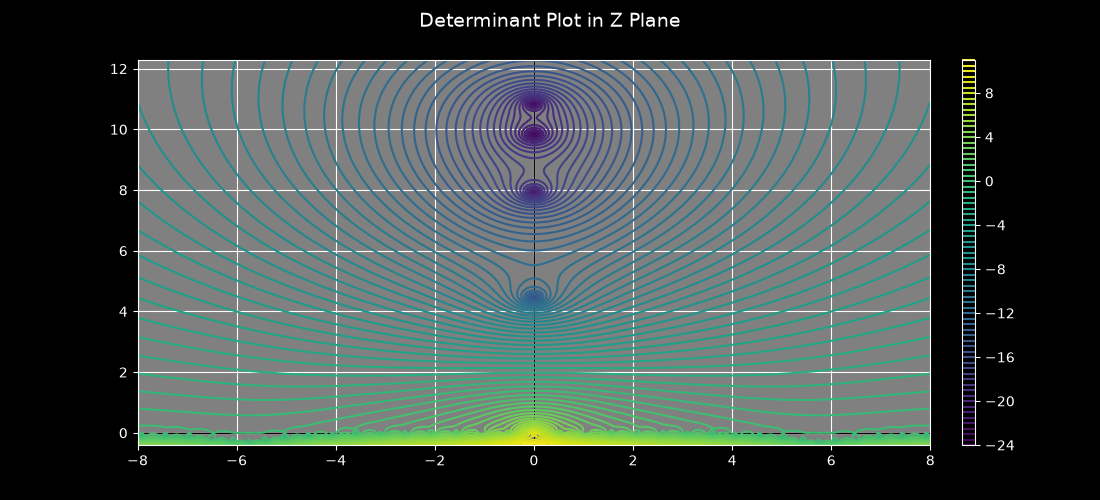

In [9]:
A.eigenvalue_plot(-8, 8, -.4, 1.1 * A.Z_max_guided.imag);

Finding their propagation constants is the same is in other cases:

In [10]:
A.get_guided_propagation_constants()
A.plot_points(A.guided_prop_constants)

In [12]:
A.guided_prop_constants[0]

np.complex128(10.8453447955239j)

However, finding the guided mode profiles is numerically difficult:

In [7]:
A.get_guided_modes()

/home/pv/local/slab2/slab.py:1134: UserWarning: Provided mode type guided, but coefficients in outer region do not align with this. User may wish to check supplied propagation constant and/or rounding parameter.
  warn(


The above should yield a warning when first run stating that the coefficients in the outer regions do not appear to correspond to a guided mode.  If we plot a mode we can see the issue more clearly:

(<Figure size 1100x500 with 1 Axes>, <Axes: >)

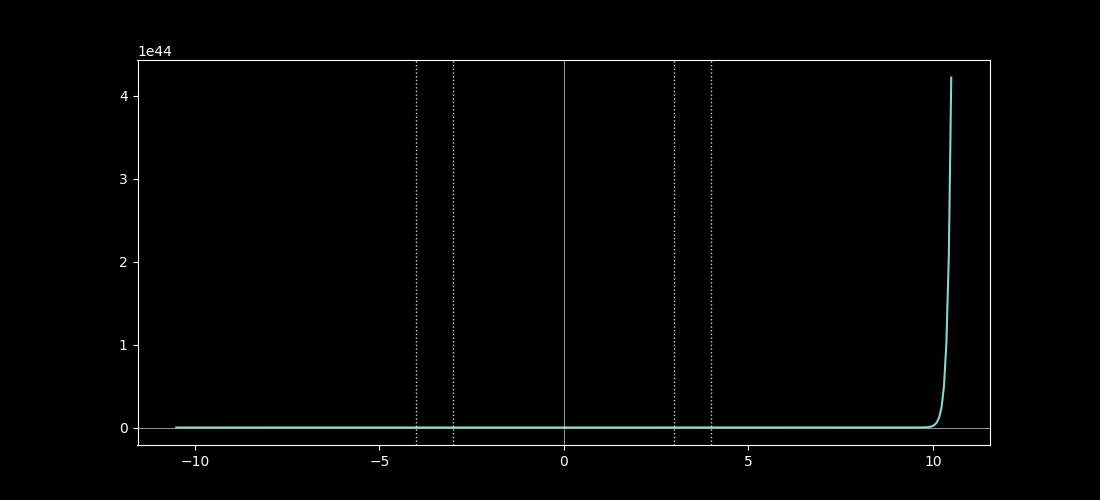

In [8]:
A.plot_field_1d(A.guided_modes[0])

Because our primary interest in this waveguide lies in its radiation field, we leave the finding of guided mode profiles aside for now.  We facilitate this by restricting our interest to an input field that does not overlap the high index walls where the guided modes are localized.  This will result in an induced field with trivial guided portion in any case.

In [68]:
A.guided_modes = []

# Radiation Field

We begin as always with initiating a propagator:

In [69]:
P = Propagator(A, f0=f0, window=[Lx, Rx], calculate_guided_field=False)

We now begin to add contours.  This will turn out to be a delicate process:

In [70]:
Np = 150
Lz = .001
Rz = 1

P.add_contour(real_contour(Lz, Rz, Np))

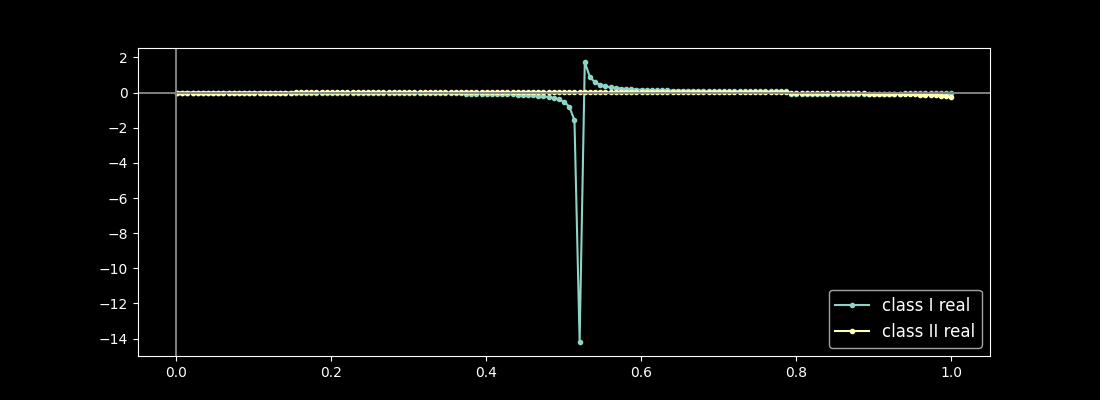

In [71]:
P.plot_transform();

These kinds of spike features will be the norm.  Our task is thus to find there locations and resolve them in the following manner:

In [72]:
Np = 120
Lz = .515
Rz = .525

P.add_contour(real_contour(Lz, Rz, Np))

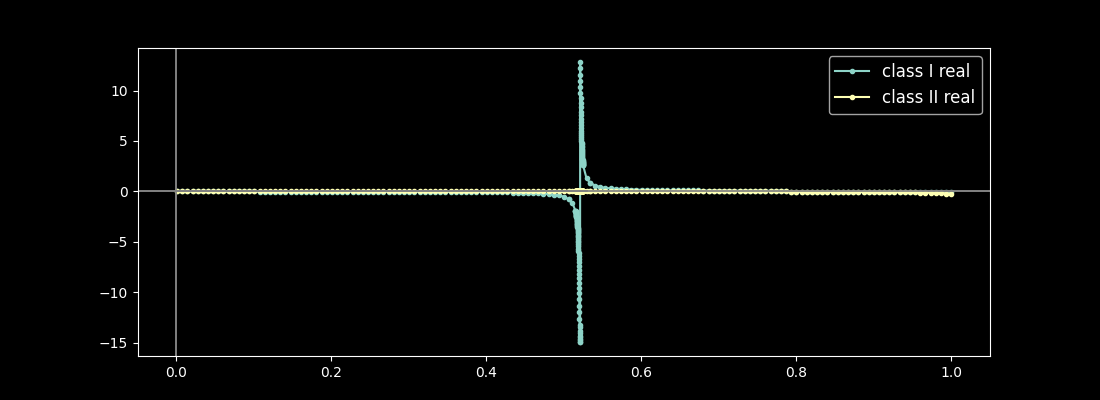

In [73]:
P.plot_transform();

To save time, we perform the transform over a large range in one go with many sample points, then refine where necessary:

In [74]:
Np = 800
Lz = 1
Rz = A.Z_evanescent

P.add_contour(real_contour(Lz, Rz, Np))

(<Figure size 1100x400 with 1 Axes>, <Axes: >)

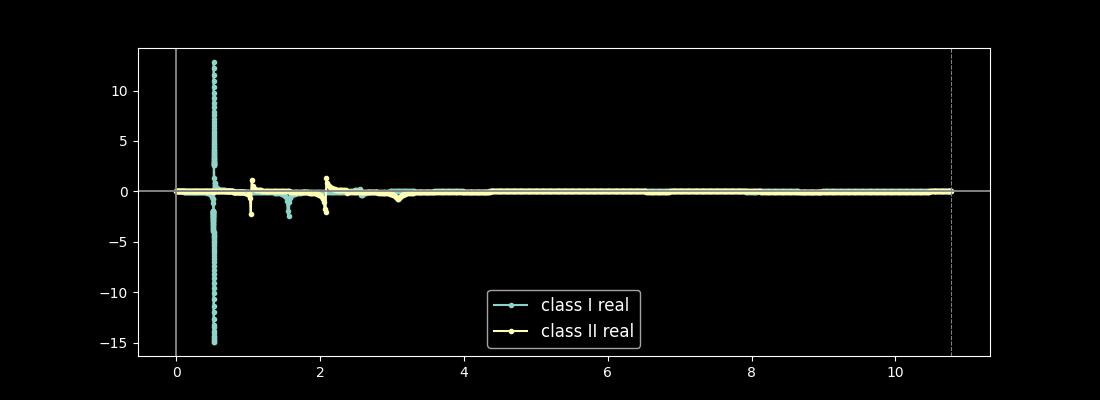

In [75]:
P.plot_transform()

The primary spikes are near 1, 1.5 and 2.1, so we refine there:

In [76]:
P.add_contour(real_contour(1.02, 1.06, 50))
P.add_contour(real_contour(1.53, 1.58, 50))
P.add_contour(real_contour(2.05, 2.1, 50))

(<Figure size 1100x400 with 1 Axes>, <Axes: >)

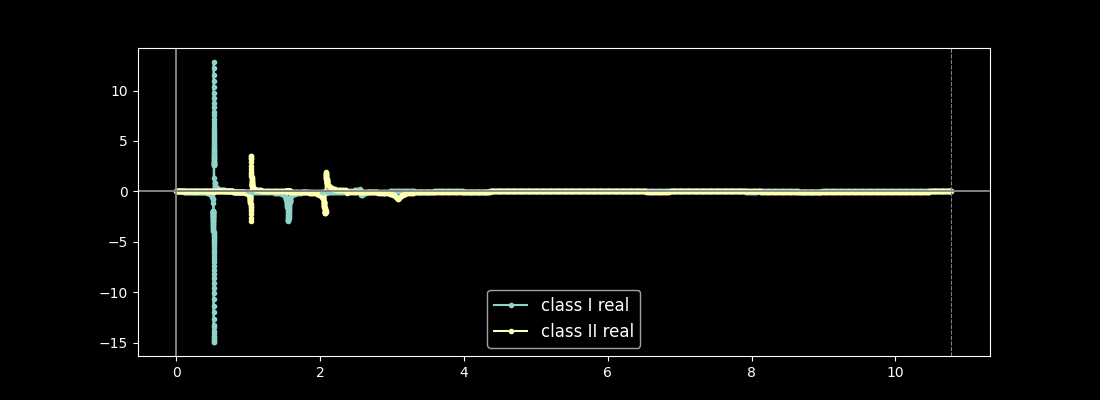

In [77]:
P.plot_transform()

Checking on progress

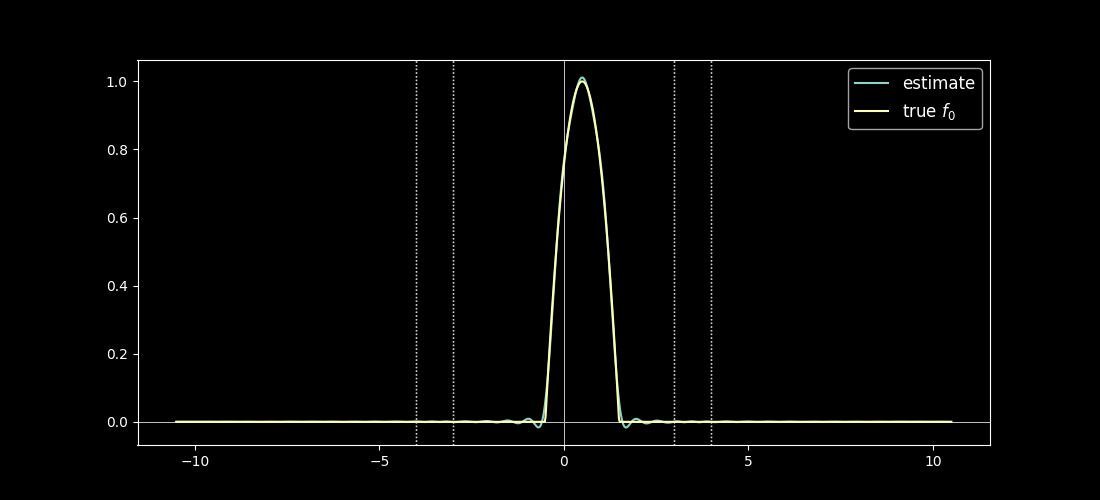

In [79]:
A.plot_field_1d(P, label='estimate') 
A.add_1d_plot(f0, label='true $f_0$')

We are getting close.  Now we continue integrating into the evanescent region to resolve the finer details:

In [80]:
Np = 200
Lz = A.Z_evanescent
Rz = 30

P.add_contour(real_contour(Lz, Rz, Np))

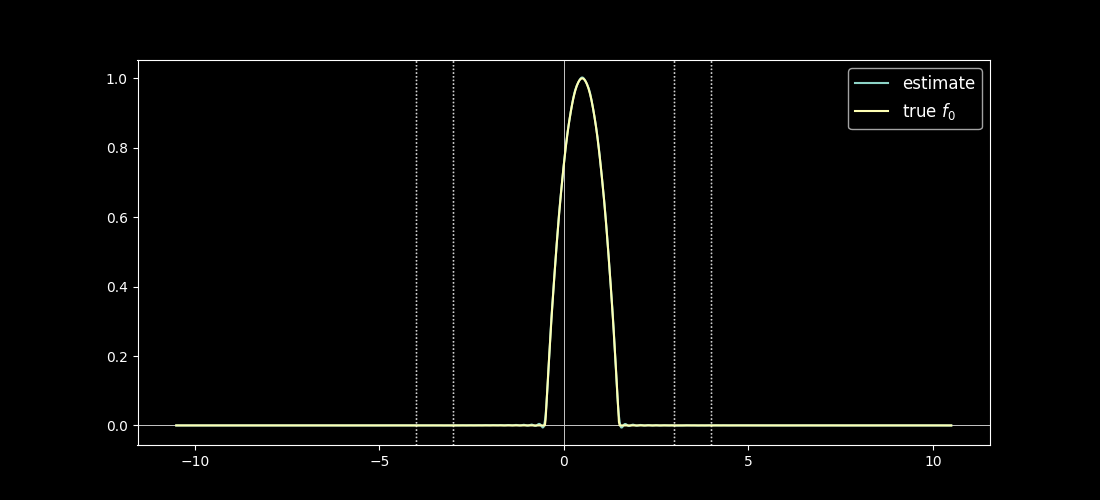

In [81]:
A.plot_field_1d(P, label='estimate') 
A.add_1d_plot(f0, label='true $f_0$')


We have resolved the input field to our desired accuracy.  Now to visualize the result:

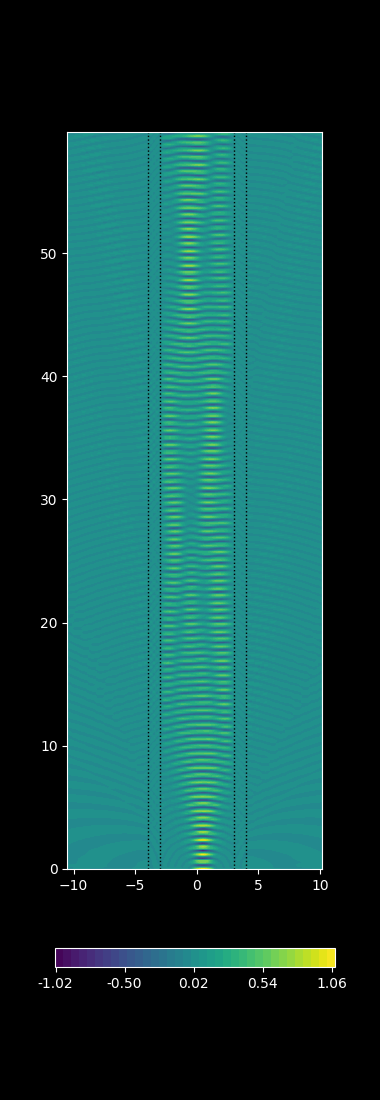

In [82]:
zmin, zmax=0, 60
A.plot_field_2d(P, zmin=zmin, zmax=zmax, zref=int((zmax-zmin)*6),
                colorbar_nticks=5, maxdim=11,
               );

# Surface Plot

The cell below generates an interactive version of this image:

![alt](surface_plot.png)

However it is slow to load and to interact with.  We are working on a threeJS interacive function for plotting the fields in 3D that should be much better.

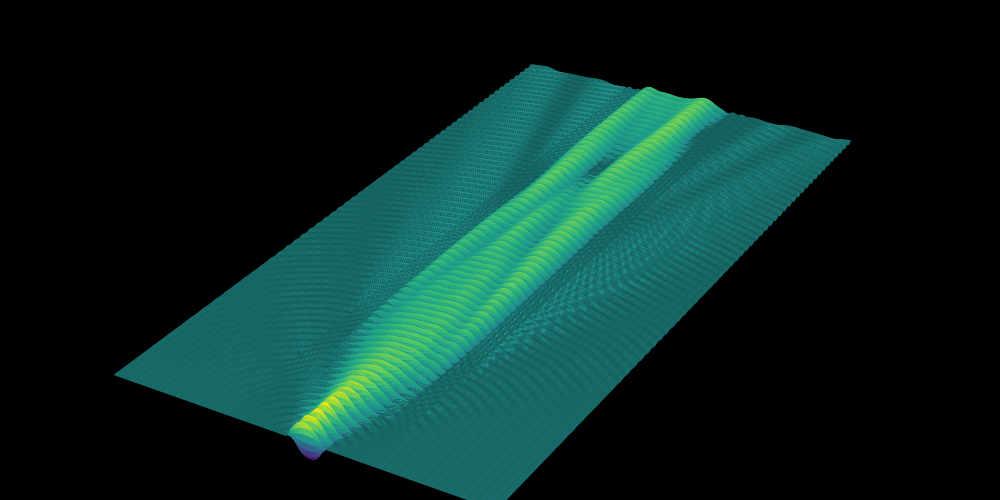

In [62]:
zmin, zmax=0, 40

A.plot_field_2d_surface(P, colorbar=False,
                        azim=-60, elev=30, zoom=2.5,
                        zmin=0, zmax=zmax, zref=int(zmax*25),
                        rstride=1, cstride=6,
                       );